In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import requests
from datetime import datetime, timedelta, timezone
from scipy.stats import pearsonr
from numpy import cov
#import emailer

In [2]:
emailer.sendEmail("email from jupyter notebook")

In [7]:
API_KEY="dcc3b2297411393438803a4a6eecab9f-65e762467abc64d0875dacfef88ab87d"
ACCOUNT_ID ="101-001-28234537-001"
OANDA_URL = 'https://api-fxpractice.oanda.com/v3/instruments/USD_MXN/candles'
# OANDA API details
oanda_api_url = "https://api-fxtrade.oanda.com/v3/instruments/USD_MXN/candles"
access_token = 'dcc3b2297411393438803a4a6eecab9f-65e762467abc64d0875dacfef88ab87d'  # Replace this with your actual OANDA API token
headers = {'Authorization': f'Bearer {access_token}'}

# Date range for the past year
current_date = datetime.now(timezone.utc)
#end_date = datetime.utcnow()

start_date = current_date - timedelta(days=1)
date_format = "%Y-%m-%dT%H:%M:%SZ"
print(start_date)

params = {
    "from": start_date.strftime(date_format),
    "to": end_date.strftime(date_format),
    "granularity": 'D'  # Daily frequency
}

# Fetch data from OANDA
response = requests.get(OANDA_URL, headers=headers, params=params)
data = response.json()


2024-04-25 11:26:14.967849+00:00


In [18]:
# Parse the USD/MXN data
""" usd_mxn = pd.DataFrame({
    'Date': [item['time'][:10] for item in data['candles']],
    'USD_MXN': [float(item['mid']['c']) for item in data['candles']]  # closing price
})

usd_mxn['Date'] = pd.to_datetime(usd_mxn['Date'])

usd_mxn.set_index('Date', inplace=True)

usd_mxn.to_excel("usd_mxn.xlsx")
start_date="2024-30-04" """

# Fetch VIX data from yfinance
vix = yf.download('^VIX', start="2020-04-30", end="2024-04-30", interval='1d')
#vix = yf.download('^VIX', period='1d', interval='1m')
vix = vix.reset_index()

print(vix.head())
day = vix.loc[vix['Date'] == '2022-05-24']
print(day['High'])

#vix = vix[['Adj Close']]

#vix.rename(columns={'Adj Close': 'VIX'}, inplace=True)
#print(vix['VIX'].iloc[-1])

#vix.to_excel("vix.xlsx")


#result = pd.merge(usd_mxn, vix, on='index')
#print(vix.head(30))

#print(usd_mxn.head())



#print(mask)

#covariance = cov(usd_mxn, vix)
#corr, _ = pearsonr(usd_mxn, vix)

[*********************100%%**********************]  1 of 1 completed

        Date       Open       High        Low      Close  Adj Close  Volume
0 2020-04-30  30.990000  35.939999  30.930000  34.150002  34.150002       0
1 2020-05-01  38.169998  39.570000  36.590000  37.189999  37.189999       0
2 2020-05-04  39.130001  40.320000  35.529999  35.970001  35.970001       0
3 2020-05-05  34.820000  36.220001  31.950001  33.610001  33.610001       0
4 2020-05-06  32.689999  35.689999  31.680000  34.119999  34.119999       0
521    31.07
Name: High, dtype: float64


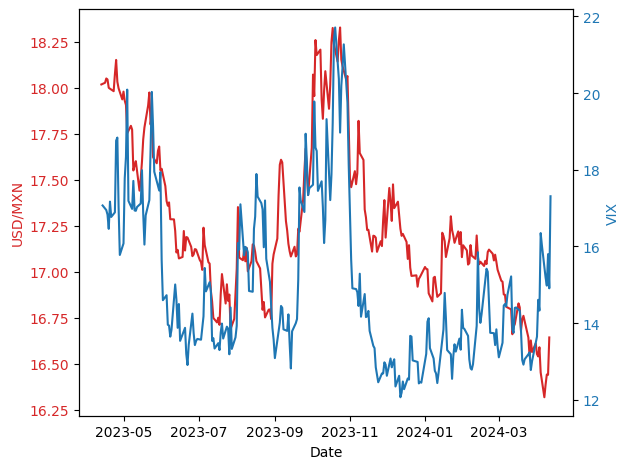

In [78]:
# Plotting
fig, ax1 = plt.subplots()

color = 'tab:red'
ax1.set_xlabel('Date')
ax1.set_ylabel('USD/MXN', color=color)
ax1.plot(usd_mxn['Date'], usd_mxn['USD_MXN'], color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:blue'
ax2.set_ylabel('VIX', color=color)
ax2.plot(vix.index, vix['VIX'], color=color)
ax2.tick_params(axis='y', labelcolor=color)

fig.tight_layout()  # otherwise the right y-label is slightly clipped
plt.show()